# 04 · Diagnostics and remedies: does each champion meet the assumptions of OLS?

Notebook 03 chose models that are economically signed and significant. This notebook asks whether their **inference and projections can be trusted**, testing each OLS assumption and trying the standard remedy when one fails:

| Assumption | Test | Remedy tried |
|---|---|---|
| Constant error variance | Breusch–Pagan, White | WLS; robust (HC/HAC) standard errors |
| Normal errors | Jarque–Bera, Q-Q plot | Target transform (raw / log / logit / Box-Cox) |
| No autocorrelation | Breusch–Godfrey, Ljung–Box (Durbin–Watson is invalid with a lagged dependent variable) | Newey–West errors, HAC lag sensitivity |
| Correct functional form | Ramsey RESET | Asymmetric (hinge) effects, polynomial, interactions |
| No undue influence | Leverage, Cook's distance, DFBETAS | Refit without influential quarters; Huber robust regression |
| Stable parameters | Chow tests, CUSUM, recursive estimates | Step dummies at reporting breaks |
| No omitted driver | Add the credit cycle | Challenger feature |

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import (
    acorr_breusch_godfrey, acorr_ljungbox, breaks_cusumolsresid, het_breuschpagan, het_white, linear_reset,
)
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.tsa.stattools import adfuller

from ukstress.config import BCST_PATHS_FILE, MODELS_DIR, PORTFOLIOS
from ukstress.features.build import inv_logit_pct, scenario_macro, trailing_loss_rate
from ukstress.ingest.build_panel import build_macro, build_panel
from ukstress.ingest.readers import read_bcst_paths
from ukstress.models.satellite import Spec, design, fit, load_models, project, sample, target
from ukstress.viz import BLUE, GREY, ORANGE, PORTFOLIO_COLOURS, fig_title, save, set_style, subtitle

warnings.filterwarnings("ignore")
set_style()
pd.set_option("display.width", 180, "display.precision", 3, "display.max_colwidth", 80)

panel, macro = build_panel(), build_macro()
champions = load_models(MODELS_DIR / "champions.json")
LABEL = {p: s["label"] for p, s in PORTFOLIOS.items()}

def ols(p, spec=None, **kw):
    """Plain OLS results (diagnostic tests need the non-robust fit) plus the (y, X) sample."""
    spec = spec or champions[p].spec
    y, X = sample(spec, target(panel, p), macro, **kw)
    return sm.OLS(y, X).fit(), y, X

## 1. The residual test battery
p-values below 0.05 reject the assumption.

In [2]:
rows = {}
for p in PORTFOLIOS:
    r, y, X = ols(p)
    e = r.resid
    rows[LABEL[p]] = {
        "Breusch–Pagan p (heteroskedasticity)": het_breuschpagan(e, X)[1],
        "White p (heteroskedasticity)": het_white(e, X)[1],
        "Jarque–Bera p (normality)": jarque_bera(e)[1],
        "skew": stats.skew(e), "excess kurtosis": stats.kurtosis(e),
        "Durbin–Watson (invalid here, shown for reference)": durbin_watson(e),
        "Breusch–Godfrey p, 4 lags (autocorrelation)": acorr_breusch_godfrey(r, nlags=4)[1],
        "Ljung–Box p, 8 lags": acorr_ljungbox(e, lags=[8]).lb_pvalue.iloc[0],
        "RESET p (functional form)": linear_reset(r, power=2, use_f=True).pvalue,
        "ADF p on residuals (stationarity)": adfuller(e)[1],
    }
battery = pd.DataFrame(rows)
battery

,Credit cards,Other consumer credit,Mortgages,Corporate (PNFC)
Breusch–Pagan p (heteroskedasticity),5.135e-01,1.803e-04,1.892e-02,9.552e-01
White p (heteroskedasticity),1.670e-02,1.777e-03,1.520e-02,5.510e-01
Jarque–Bera p (normality),1.527e-03,4.653e-01,1.268e-01,1.962e-01
skew,-7.827e-01,-2.704e-01,-4.415e-01,2.756e-01
excess kurtosis,1.994e-01,3.630e-02,-1.161e-01,-5.671e-01
"Durbin–Watson (invalid here, shown for reference)",3.576e-01,3.288e-01,3.613e-01,5.151e-01
"Breusch–Godfrey p, 4 lags (autocorrelation)",2.442e-17,6.223e-19,4.651e-19,1.550e-14
"Ljung–Box p, 8 lags",1.391e-31,4.885e-33,2.042e-26,2.709e-21
RESET p (functional form),6.464e-02,5.352e-01,2.870e-04,9.401e-02
ADF p on residuals (stationarity),2.232e-01,5.702e-01,2.391e-02,2.823e-03


**Reading:**
- **Autocorrelation is rejected everywhere.** This is expected: the trailing four-quarter target overlaps, so residuals follow a moving-average pattern of order 3 by construction. That does not bias the coefficients, but it invalidates classical standard errors, which is why the models use Newey–West errors. Section 3 checks that conclusions do not depend on the Newey–West lag length.
- **The standard ADF test cannot reject a unit root in the card and other-consumer residuals.** If true, these would be spurious regressions. But ADF has notoriously low power when errors have a moving-average structure like this one. The next cell checks stationarity three better-suited ways.
- Heteroskedasticity is rejected for other consumer credit and mortgages, normality for cards, and functional form (RESET) for mortgages. These are taken up below.

In [3]:
from statsmodels.tsa.stattools import kpss

rows = {}
for p in PORTFOLIOS:
    e = ols(p)[0].resid
    rows[LABEL[p]] = {"KPSS p (H0: stationary)": kpss(e, nlags="auto")[1],
                      "ADF p, non-overlapping quarters": adfuller(e.iloc[::4], maxlag=1)[1],
                      "autocorrelation lag 1": e.autocorr(1), "lag 4": e.autocorr(4), "lag 8": e.autocorr(8)}
pd.DataFrame(rows).T

,KPSS p (H0: stationary),"ADF p, non-overlapping quarters",autocorrelation lag 1,lag 4,lag 8
Credit cards,0.100,9.199e-05,0.817,0.229,0.031
Other consumer credit,0.076,1.994e-04,0.834,0.179,-0.236
Mortgages,0.100,8.562e-07,0.818,-0.060,-0.108
Corporate (PNFC),0.100,3.900e-03,0.739,0.096,0.015


Residual autocorrelation is high at lag 1 but has largely died out by lag 4 and is gone by lag 8. That is the signature of the three-quarter overlap, not of a unit root (which would decay slowly). KPSS does not reject stationarity, and ADF on non-overlapping quarters (every fourth observation, removing the overlap) rejects a unit root for every portfolio. **Conclusion: the residuals are stationary; the champions are not spurious regressions.**

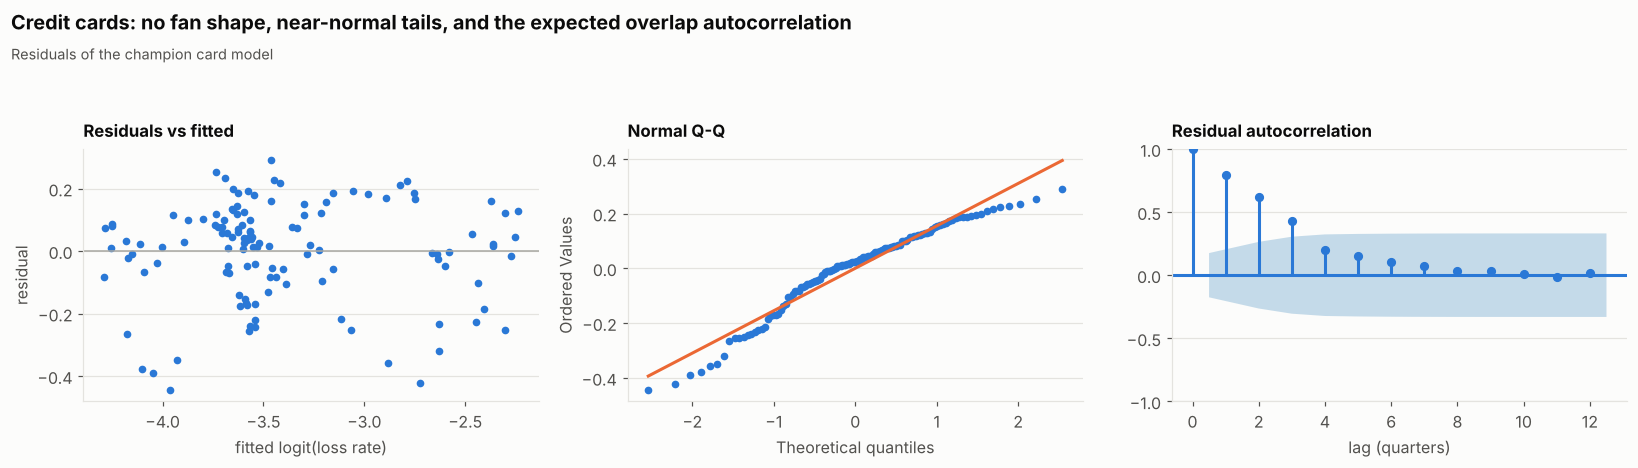

In [4]:
p = "credit_card"
r, y, X = ols(p)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
axes[0].scatter(r.fittedvalues, r.resid, s=16, color=BLUE)
axes[0].axhline(0, color=GREY, lw=1)
axes[0].set(xlabel="fitted logit(loss rate)", ylabel="residual")
axes[0].set_title("Residuals vs fitted", fontsize=11, pad=8)
stats.probplot(r.resid, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set(color=BLUE, markersize=4)
axes[1].get_lines()[1].set(color=ORANGE)
axes[1].set_title("Normal Q-Q", fontsize=11, pad=8)
plot_acf(r.resid, ax=axes[2], lags=12, color=BLUE, vlines_kwargs={"colors": BLUE}, title="")
axes[2].set_title("Residual autocorrelation", fontsize=11, pad=8)
axes[2].set_xlabel("lag (quarters)")
fig_title(fig, "Credit cards: no fan shape, near-normal tails, and the expected overlap autocorrelation",
          "Residuals of the champion card model")
save(fig, "04_card_residuals")
fig

## 2. Influential quarters
Cook's distance flags quarters that move all fitted values; DFBETAS flags quarters that move a *specific* coefficient by more than $2/\sqrt{n}$ standard errors. The question that matters for a stress test: **do the macro coefficients survive when the most influential quarters are removed?**

In [5]:
infl_rows, refit_rows = [], {}
for p in PORTFOLIOS:
    r, y, X = ols(p)
    inf = r.get_influence()
    cooks = pd.Series(inf.cooks_distance[0], index=y.index)
    flagged = cooks[cooks > 4 / len(y)].sort_values(ascending=False)
    infl_rows.append({"portfolio": LABEL[p], "quarters with Cook's D > 4/n": len(flagged),
                      "top 3": ", ".join(str(q) for q in flagged.index[:3])})
    keep = ~y.index.isin(flagged.index)
    r2 = sm.OLS(y[keep], X[keep]).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
    base = champions[p].params
    macro_terms = [c for c in base.index if c not in ("const", "covid", "y_L4")]
    for c in macro_terms + ["y_L4"]:
        refit_rows[(LABEL[p], c)] = {"champion": base[c], "without influential quarters": r2.params[c],
                                     "change %": 100 * (r2.params[c] / base[c] - 1), "p-value after": r2.pvalues[c]}
display(pd.DataFrame(infl_rows).set_index("portfolio"))
pd.DataFrame(refit_rows).T

,quarters with Cook's D > 4/n,top 3
portfolio,,
Credit cards,6,"1995Q3, 1995Q2, 2012Q4"
Other consumer credit,9,"2018Q4, 2020Q2, 2019Q1"
Mortgages,6,"2020Q2, 2017Q3, 2017Q2"
Corporate (PNFC),6,"2020Q4, 2020Q2, 2009Q4"


champion  without influential quarters  change %  p-value after
Credit cards          unemployment_chg_yoy_L2       0.148                         0.113   -23.569      2.257e-04
                      bank_rate_L8                  0.030                         0.034    15.105      1.929e-05
                      y_L4                          0.874                         0.908     3.804      4.561e-76
Other consumer credit unemployment_chg_yoy_L2       0.111                         0.113     1.296      2.289e-02
                      y_L4                          0.858                         0.852    -0.750      9.320e-22
Mortgages             unemployment_L2               0.229                         0.178   -22.422      1.618e-02
                      house_price_growth_yoy_L1    -0.035                        -0.032    -9.345      5.002e-03
                      bank_rate_L8                  0.097                         0.078   -19.612      5.481e-03
                      y_L4                          0.522                         0.586    12.399      1.604e-08
Corporate (PNFC)      unemployment_L0               0.209                         0.184   -11.871      1.016e-09
                      gdp_growth_yoy_L6            -0.023                        -0.022    -1.201      1.713e-06
                      y_L4                          0.615                         0.647     5.320      8.042e-36

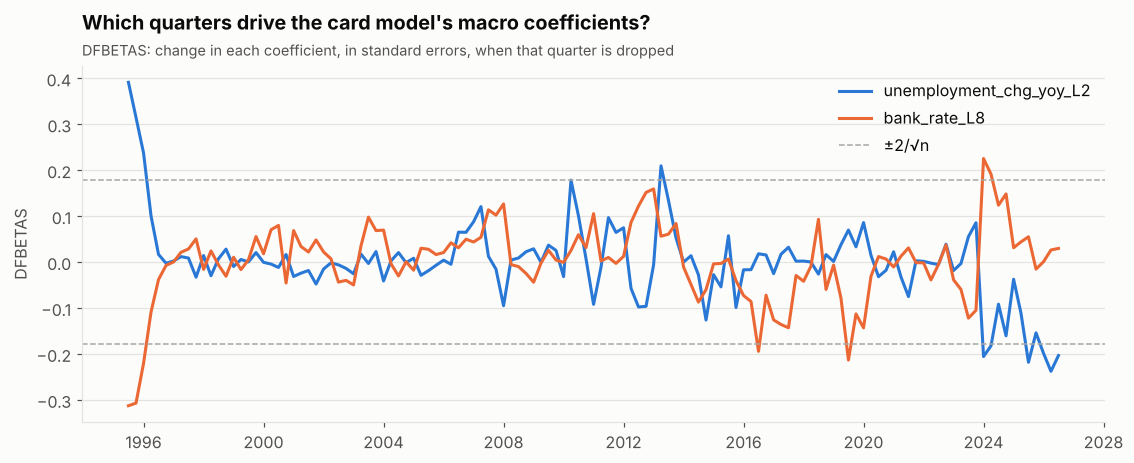

In [6]:
p = "credit_card"
r, y, X = ols(p)
dfb = pd.DataFrame(r.get_influence().dfbetas, index=y.index, columns=X.columns)
fig, ax = plt.subplots(figsize=(12, 4.2))
t = y.index.to_timestamp(how="end")
for c, colour in [("unemployment_chg_yoy_L2", BLUE), ("bank_rate_L8", ORANGE)]:
    ax.plot(t, dfb[c], color=colour, label=c)
ax.axhline(2 / np.sqrt(len(y)), color=GREY, ls="--", lw=1)
ax.axhline(-2 / np.sqrt(len(y)), color=GREY, ls="--", lw=1, label="±2/√n")
ax.legend(loc="upper right")
ax.set_ylabel("DFBETAS")
ax.set_title("Which quarters drive the card model's macro coefficients?")
subtitle(ax, "DFBETAS: change in each coefficient, in standard errors, when that quarter is dropped")
save(fig, "04_card_dfbetas")
fig

## 3. Remedies for the error structure
### 3a. Newey–West lag length
The Newey–West bandwidth is a choice. A common rule is $4(n/100)^{2/9} \approx 4$ for 125 quarters, which matches the overlap of the target. Conclusions should not hinge on it.

In [7]:
rows = {}
for p in PORTFOLIOS:
    y, X = sample(champions[p].spec, target(panel, p), macro)
    for L in [0, 2, 4, 8, 12]:
        rr = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": L}) if L else sm.OLS(y, X).fit()
        macro_terms = [c for c in X.columns if c not in ("const", "covid", "y_L4")]
        rows[(LABEL[p], "classical" if L == 0 else f"NW {L} lags")] = {
            "smallest |t| among macro terms": rr.tvalues[macro_terms].abs().min(),
            "all macro terms p < 0.05": bool((rr.pvalues[macro_terms] < 0.05).all())}
pd.DataFrame(rows).T.unstack(level=1)["smallest |t| among macro terms"].round(2)

,NW 12 lags,NW 2 lags,NW 4 lags,NW 8 lags,classical
Corporate (PNFC),5.136,4.642,4.744,5.222,4.046
Credit cards,2.477,3.26,2.88,2.641,4.291
Mortgages,2.6,2.89,2.58,2.487,4.254
Other consumer credit,1.945,2.448,2.144,1.963,3.297


### 3b. Weighted least squares and Huber robust regression
- **WLS** down-weights quarters with high error variance, modelled by regressing |residual| on the fitted value (feasible GLS).
- **Huber M-estimation** down-weights large residuals rather than deleting them, so a few block write-offs cannot drag the line.

If both agree with OLS, heteroskedasticity and outliers are not distorting the coefficients.

In [8]:
rows = {}
for p in PORTFOLIOS:
    r, y, X = ols(p)
    aux = sm.OLS(np.abs(r.resid), sm.add_constant(r.fittedvalues)).fit()
    sd_hat = np.clip(aux.fittedvalues, 1e-3, None)
    wls = sm.WLS(y, X, weights=1 / sd_hat**2).fit()
    rlm = sm.RLM(y, X, M=sm.robust.norms.HuberT()).fit()
    for c in X.columns:
        if c in ("const", "covid"):
            continue
        rows[(LABEL[p], c)] = {"OLS": r.params[c], "WLS": wls.params[c], "Huber": rlm.params[c]}
rem = pd.DataFrame(rows).T
rem["max change vs OLS, %"] = 100 * (rem[["WLS", "Huber"]].sub(rem.OLS, axis=0).abs().max(axis=1) / rem.OLS.abs())
rem.round(3)

OLS    WLS  Huber  max change vs OLS, %
Credit cards          unemployment_chg_yoy_L2    0.148  0.147  0.134                 9.650
                      bank_rate_L8               0.030  0.027  0.032                 7.589
                      y_L4                       0.874  0.879  0.887                 1.438
Other consumer credit unemployment_chg_yoy_L2    0.111  0.155  0.120                39.689
                      y_L4                       0.858  0.799  0.829                 6.853
Mortgages             unemployment_L2            0.229  0.202  0.196                14.529
                      house_price_growth_yoy_L1 -0.035 -0.034 -0.034                 4.645
                      bank_rate_L8               0.097  0.095  0.090                 7.621
                      y_L4                       0.522  0.506  0.554                 6.318
Corporate (PNFC)      unemployment_L0            0.209  0.210  0.207                 0.971
                      gdp_growth_yoy_L6         -0.023 -0.023 -0.022                 1.892
                      y_L4                       0.615  0.611  0.617                 0.599

## 4. Does the target transform matter?
The champion card model is refitted with the same drivers on three scales: the raw rate, its log, and its logit. A Box–Cox fit on the rate estimates which power transform makes it most symmetric. Fit statistics are not comparable across transforms, so the comparison uses what matters for the stress test: **the projected peak loss rate under the 2025 scenario.**

In [9]:
lam = stats.boxcox(trailing_loss_rate(panel, "credit_card").dropna())[1]
print(f"Box-Cox λ for the card loss rate: {lam:.2f}   (λ = 0 is the log; λ = 1 is no transform)")

path = scenario_macro(macro)
spec = champions["credit_card"].spec
rate = trailing_loss_rate(panel, "credit_card")
transforms = {
    "raw rate": (lambda r: r, lambda z: z),
    "log": (np.log, np.exp),
    "logit": (lambda r: np.log((r / 100) / (1 - r / 100)), lambda z: 100 / (1 + np.exp(-z))),
}
rows = {}
for name, (f, finv) in transforms.items():
    yt = f(rate).rename("y")
    fm, res = fit(spec, yt, macro)
    # project on the transformed scale, then map back; project() applies inv-logit, so undo it first
    pr = project(fm, yt, path)
    z = np.log((pr.central / 100) / (1 - pr.central / 100))
    rows[name] = {"JB p": jarque_bera(res.resid)[1], "skew": stats.skew(res.resid),
                  "peak card loss under scenario, %": finv(z).max(), "sign rules hold": bool(
                      (res.params.drop(["const", "covid"]) > 0).all())}
pd.DataFrame(rows).T

Box-Cox λ for the card loss rate: -0.31   (λ = 0 is the log; λ = 1 is no transform)


,JB p,skew,"peak card loss under scenario, %",sign rules hold
raw rate,0.089,-0.41,7.408,True
log,0.001,-0.802,6.289,True
logit,0.002,-0.783,6.367,True


## 5. Functional form: non-linear and interaction effects
### 5a. Do rising and falling unemployment matter equally?
A hinge splits the unemployment change into its positive and negative parts. If losses rise faster when unemployment rises than they fall when it falls, a symmetric model *understates* stress losses.

In [10]:
def augmented_ols(p, extra: pd.DataFrame):
    y, X = sample(champions[p].spec, target(panel, p), macro)
    X = X.join(extra).dropna()
    return sm.OLS(y.loc[X.index], X).fit(cov_type="HAC", cov_kwds={"maxlags": 4})

du = macro["unemployment_chg_yoy"].shift(2)
rows = {}
for p in ["credit_card", "other_consumer"]:
    y, X = sample(champions[p].spec, target(panel, p), macro)
    Xh = X.drop(columns="unemployment_chg_yoy_L2").assign(du_up=du.clip(lower=0), du_down=du.clip(upper=0))
    rh = sm.OLS(y, Xh.loc[y.index]).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
    w = rh.wald_test("du_up = du_down", scalar=True)
    rows[LABEL[p]] = {"effect of rising unemployment": rh.params["du_up"],
                      "effect of falling unemployment": rh.params["du_down"],
                      "p (equal effects)": float(w.pvalue)}
pd.DataFrame(rows).T

,effect of rising unemployment,effect of falling unemployment,p (equal effects)
Credit cards,0.132,0.167,0.656
Other consumer credit,0.141,0.080,0.657


### 5b. The "double trigger" in mortgages
Mortgage theory says default needs two things at once: a borrower who cannot pay (unemployment) *and* no equity to sell out (falling house prices). That is an **interaction**: unemployment should hurt more when house prices are falling.

In [11]:
u2 = macro["unemployment"].shift(2) - macro["unemployment"].mean()
hp1 = macro["house_price_growth_yoy"].shift(1) - macro["house_price_growth_yoy"].mean()
ri = augmented_ols("mortgage", (u2 * hp1).rename("unemployment x house_prices"))
ri.summary2().tables[1].loc[["unemployment_L2", "house_price_growth_yoy_L1", "unemployment x house_prices"]]

,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
unemployment_L2,0.285,0.094,3.029,0.002,0.101,0.470
house_price_growth_yoy_L1,-0.026,0.016,-1.663,0.096,-0.057,0.005
unemployment x house_prices,0.019,0.011,1.663,0.096,-0.003,0.042


### 5c. Quadratic unemployment for corporate losses

In [12]:
uq = (macro["unemployment"] - macro["unemployment"].mean()) ** 2
rq = augmented_ols("corporate", uq.rename("unemployment_sq"))
rq.summary2().tables[1].loc[["unemployment_L0", "unemployment_sq"]]

,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
unemployment_L0,0.208,0.038,5.467,4.589e-08,0.134,0.283
unemployment_sq,0.014,0.019,0.720,4.716e-01,-0.024,0.051


## 6. Parameter stability
### 6a. Chow test: did the relationship change after the 2008 crisis?
Fit separately before and after 2008 Q1 and compare with the pooled fit: $F = \frac{(RSS_p - RSS_1 - RSS_2)/k}{(RSS_1 + RSS_2)/(n - 2k)}$.

In [13]:
def chow(p, split="2008Q1"):
    r, y, X = ols(p)
    pre, post = y.index < pd.Period(split), y.index >= pd.Period(split)
    X = X.drop(columns="covid")  # COVID dummy is zero before the split
    k = X.shape[1]
    rss_p = sm.OLS(y, X).fit().ssr
    rss1, rss2 = sm.OLS(y[pre], X[pre]).fit().ssr, sm.OLS(y[post], X[post]).fit().ssr
    f = ((rss_p - rss1 - rss2) / k) / ((rss1 + rss2) / (len(y) - 2 * k))
    return f, stats.f.sf(f, k, len(y) - 2 * k)

pd.DataFrame({LABEL[p]: dict(zip(["Chow F at 2008Q1", "p"], chow(p), strict=True)) for p in PORTFOLIOS}).T

,Chow F at 2008Q1,p
Credit cards,8.021,9.477e-06
Other consumer credit,7.118,1.938e-04
Mortgages,5.614,1.147e-04
Corporate (PNFC),5.032,8.891e-04


Classical Chow tests assume independent errors, which these residuals are not, so a small p-value overstates the evidence. The recursive estimates and CUSUM test below are more informative about *how* the parameters move.

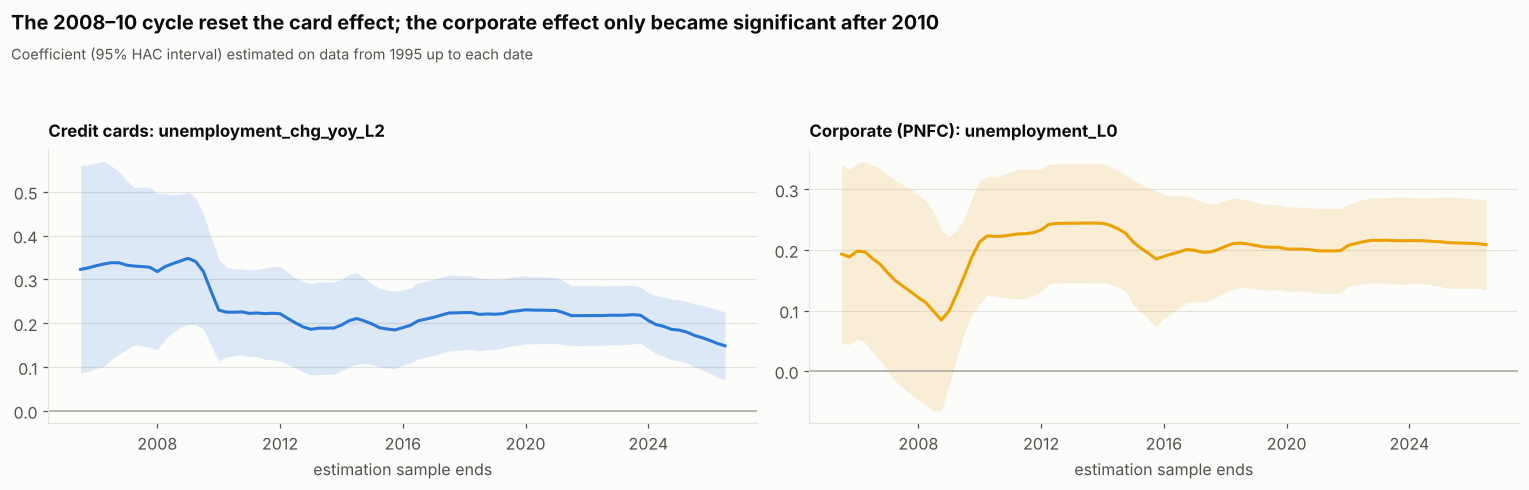

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, p, c in [(axes[0], "credit_card", "unemployment_chg_yoy_L2"), (axes[1], "corporate", "unemployment_L0")]:
    y, X = sample(champions[p].spec, target(panel, p), macro)
    ends = y.index[40:]
    est, lo, hi = [], [], []
    for e in ends:
        rr = sm.OLS(y.loc[:e], X.loc[:e]).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
        est.append(rr.params[c])
        ci = rr.conf_int().loc[c]
        lo.append(ci[0]); hi.append(ci[1])
    tt = ends.to_timestamp(how="end")
    ax.fill_between(tt, lo, hi, color=PORTFOLIO_COLOURS[p], alpha=0.15, lw=0)
    ax.plot(tt, est, color=PORTFOLIO_COLOURS[p])
    ax.axhline(0, color=GREY, lw=1)
    ax.set_title(f"{LABEL[p]}: {c}", fontsize=11, pad=8)
    ax.set_xlabel("estimation sample ends")
fig_title(fig, "The 2008–10 cycle reset the card effect; the corporate effect only became significant after 2010",
          "Coefficient (95% HAC interval) estimated on data from 1995 up to each date")
save(fig, "04_recursive_coefficients")
fig

In [15]:
pd.DataFrame({LABEL[p]: {"CUSUM statistic": breaks_cusumolsresid(ols(p)[0].resid, ddof=ols(p)[0].df_model)[0],
                         "p (parameter stability)": breaks_cusumolsresid(ols(p)[0].resid, ddof=ols(p)[0].df_model)[1]}
              for p in PORTFOLIOS}).T

,CUSUM statistic,p (parameter stability)
Credit cards,1.128,1.570e-01
Other consumer credit,2.221,1.042e-04
Mortgages,1.364,4.846e-02
Corporate (PNFC),1.429,3.372e-02


### 6b. Reporting breaks found in the EDA
The card balance series jumps in 2010 Q1 and 2013 Q1. A step dummy from each date tests whether the loss rate shifted for accounting reasons.

In [16]:
rows = {}
for q in ["2010Q1", "2013Q1"]:
    step = pd.Series((macro.index >= pd.Period(q)).astype(float), index=macro.index, name=f"step_{q}")
    rr = augmented_ols("credit_card", step)
    rows[q] = {"step coefficient": rr.params[step.name], "p": rr.pvalues[step.name],
               "Δu coef with step": rr.params["unemployment_chg_yoy_L2"],
               "Δu coef champion": champions["credit_card"].params["unemployment_chg_yoy_L2"]}
pd.DataFrame(rows).T

,step coefficient,p,Δu coef with step,Δu coef champion
2010Q1,-0.168,0.078,0.179,0.148
2013Q1,-0.007,0.957,0.150,0.148


## 7. Omitted driver: the credit cycle
The EDA found card losses at ~6% in 2004–06 with unemployment low: a lending boom, then insolvencies. The scenario workbook includes **consumer credit growth** (12-month growth of lending to individuals), available from 2000. Adding it two years earlier tests whether rapid lending growth predicts later losses.

In [17]:
b = read_bcst_paths(BCST_PATHS_FILE)
cc = b["Consumer credit to UK individuals"].reindex(macro.index)
rows = {}
for lag in [4, 8, 12]:
    rr = augmented_ols("credit_card", cc.shift(lag).rename(f"credit_growth_L{lag}"))
    rows[f"lag {lag}"] = {"coef": rr.params.iloc[-1], "p": rr.pvalues.iloc[-1], "n": int(rr.nobs),
                          "Δu coef": rr.params["unemployment_chg_yoy_L2"]}
pd.DataFrame(rows).T

,coef,p,n,Δu coef
lag 4,0.011,0.045,102.0,0.118
lag 8,0.011,0.051,98.0,0.106
lag 12,0.014,0.005,94.0,0.126


## Findings and decisions

| # | Finding | Decision |
|---|---|---|
| 1 | Residual autocorrelation everywhere (Breusch–Godfrey p ≈ 0), dying out by lag 4–8: the overlap of the trailing target | Keep Newey–West errors (4 lags). Conclusions hold from 2 to 12 lags for cards, mortgages and corporate |
| 2 | Standard ADF fails to confirm stationary residuals for cards and other consumer credit, but KPSS and ADF on non-overlapping quarters do | Not spurious regressions; the ADF failure is low power under MA errors |
| 3 | **Other consumer credit is fragile:** t falls to 1.95 with 12 Newey–West lags; WLS moves its unemployment effect by +40%; CUSUM rejects stability | Rated *low confidence*; projected alongside its challenger in notebooks 06–07 |
| 4 | Heteroskedasticity in other consumer credit and mortgages | Newey–West errors are also heteroskedasticity-robust; WLS and Huber move card and corporate coefficients by < 10% |
| 5 | Card residuals are negatively skewed (JB p = 0.002): a few quarters where losses came in well below the model | Projection intervals resample actual residuals (block bootstrap) rather than assume normal errors |
| 6 | **Transform choice is material:** the same card drivers on the raw rate give a scenario peak about 1 percentage point higher than logit | Keep logit (bounded, sign rules hold); report the raw-rate peak as a model-risk sensitivity in notebook 07 |
| 7 | No asymmetry in the unemployment effect (p = 0.66), no quadratic unemployment effect for corporate (p = 0.47) | Linear specification kept |
| 8 | The mortgage "double trigger" interaction is not supported (wrong sign, p = 0.10), yet RESET rejects the mortgage functional form | Mortgage model rated *low confidence*; it is also the smallest loss in £ terms |
| 9 | Chow tests reject stability at 2008 (overstated with autocorrelated errors). Recursive estimates: the card unemployment effect fell from ~0.33 to ~0.22 once 2009–10 entered the sample and has drifted to ~0.15 since 2024; the corporate effect was not significant until after 2010 | **Key limitation:** stress sensitivities are learned largely from one severe cycle, and the card sensitivity is still drifting. Monitor quarterly (notebook 06) |
| 10 | No significant step at the card reporting breaks (2010 Q1 p = 0.08; 2013 Q1 p = 0.96) | No break adjustment |
| 11 | **Consumer credit growth three years earlier predicts card losses** (p = 0.005), but its history starts only in 2000 | Recommended model enhancement; not in the champion because it would cost the 1990s data |

In [18]:
cards_t = battery[LABEL["credit_card"]]
print("Autocorrelation rejected (BG p < 0.05):", [k for k, v in battery.loc["Breusch–Godfrey p, 4 lags (autocorrelation)"].items() if v < 0.05])
print("Heteroskedasticity rejected (BP p < 0.05):", [k for k, v in battery.loc["Breusch–Pagan p (heteroskedasticity)"].items() if v < 0.05])
print("Normality rejected (JB p < 0.05):", [k for k, v in battery.loc["Jarque–Bera p (normality)"].items() if v < 0.05])
print("RESET rejected (p < 0.05):", [k for k, v in battery.loc["RESET p (functional form)"].items() if v < 0.05])
print("Residuals stationary (ADF p < 0.05):", [k for k, v in battery.loc["ADF p on residuals (stationarity)"].items() if v < 0.05])
print(f"Largest WLS/Huber coefficient change vs OLS: {rem['max change vs OLS, %'].max():.0f}%")

Autocorrelation rejected (BG p < 0.05): ['Credit cards', 'Other consumer credit', 'Mortgages', 'Corporate (PNFC)']
Heteroskedasticity rejected (BP p < 0.05): ['Other consumer credit', 'Mortgages']
Normality rejected (JB p < 0.05): ['Credit cards']
RESET rejected (p < 0.05): ['Mortgages']
Residuals stationary (ADF p < 0.05): ['Mortgages', 'Corporate (PNFC)']
Largest WLS/Huber coefficient change vs OLS: 40%
